# AI Impact on Jobs & Salaries (2020–2026)

## Exploratory Data Analysis (EDA)

This notebook explores the structure, quality, and key patterns of the
AI Impact on Jobs & Salaries dataset.

### Objectives
- Understand the dataset structure
- Inspect data types and missing values
- Identify duplicate records
- Analyze salary distributions
- Explore employment and job characteristics
- Investigate AI-related patterns in the job market
- Prepare insights for the visualization and machine learning stages

In [1]:
# Data manipulation
import  pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns" , None)
pd.set_option("display.max_rows" , 100)

# Reproducibility
RANDOM_STATE = 42

In [2]:
# Load dataset
DATA_PATH = "../data/ai_jobs_salaries_clean.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully")
print(f"Shape: {df.shape}")

Dataset loaded successfully
Shape: (71913, 17)


In [3]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [4]:
df.sample(5 , random_state = RANDOM_STATE)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
54637,2024,EN,FT,Data Analyst,90900,USD,90900,US,0,US,M,Entry-level,Full-time,On-site,False,Data Analyst,Business services and administration managers
9937,2025,SE,FT,Manager,256470,USD,256470,US,0,US,M,Senior-level,Full-time,On-site,False,Other / Unclassified,NaN
58586,2024,SE,FT,Research Scientist,192986,USD,192986,US,0,US,M,Senior-level,Full-time,On-site,False,Research Scientist,Physical and earth science professionals
49544,2024,MI,FT,Data Governance Manager,185500,USD,185500,US,0,US,M,Mid-level,Full-time,On-site,False,Other / Unclassified,NaN
33029,2025,SE,FT,Machine Learning Engineer,122500,USD,122500,US,0,US,M,Senior-level,Full-time,On-site,False,ML Engineer,Software and applications developers


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   work_year               71913 non-null  int64 
 1   experience_level        71913 non-null  object
 2   employment_type         71913 non-null  object
 3   job_title               71913 non-null  object
 4   salary                  71913 non-null  int64 
 5   salary_currency         71913 non-null  object
 6   salary_in_usd           71913 non-null  int64 
 7   employee_residence      71913 non-null  object
 8   remote_ratio            71913 non-null  int64 
 9   company_location        71913 non-null  object
 10  company_size            71913 non-null  object
 11  experience_level_label  71913 non-null  object
 12  employment_type_label   71913 non-null  object
 13  work_mode               71913 non-null  object
 14  salary_outlier_flag     71913 non-null  bool  
 15  ro

In [6]:
missing_values = df.isna().sum()
missing_summary = pd.DataFrame({
    "missing_count" : missing_values,
    "missing_percentage" : (missing_values / len(df)) *100
})

missing_summary = missing_summary.sort_values(
    by = "missing_count",
    ascending=False
)
missing_summary

,missing_count,missing_percentage
isco_group_hint,40540,56.373674
company_location,0,0.000000
role_family,0,0.000000
salary_outlier_flag,0,0.000000
work_mode,0,0.000000
employment_type_label,0,0.000000
experience_level_label,0,0.000000
company_size,0,0.000000
work_year,0,0.000000
experience_level,0,0.000000


In [7]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows : {duplicate_count :,}")
print(f"Duplicate percentage : {duplicate_count / len(df) *100:.2f}%")

Number of duplicate rows : 0
Duplicate percentage : 0.00%


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
work_year,71913.0,2024.425153,0.721198,2020.0,2024.0,2025.0,2025.0,2025.0
salary,71913.0,161710.163823,287286.815546,14000.0,96400.0,139700.0,192200.0,30400000.0
salary_in_usd,71913.0,151161.252625,77329.594122,15000.0,96000.0,138750.0,190315.0,800000.0
remote_ratio,71913.0,24.569271,42.917779,0.0,0.0,0.0,0.0,100.0


In [9]:
df.describe(include="object")

,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,experience_level_label,employment_type_label,work_mode,role_family,isco_group_hint
count,71913,71913,71913,71913,71913,71913,71913,71913,71913,71913,71913,31373
unique,4,4,422,26,104,97,3,4,4,3,11,5
top,SE,FT,Data Scientist,USD,US,US,M,Senior-level,Full-time,On-site,Other / Unclassified,Software and applications developers
freq,37702,71163,7160,65910,60085,60147,70110,37702,71163,54081,40540,12475


## Categorical Variables — Cardinality Analysis

We examine the number of unique values in each categorical column
to understand the diversity and granularity of the dataset.

In [10]:
# Number of unique values in each column
unique_counts = (
    df.nunique()
    .sort_values(ascending=False)
)
unique_counts

salary_in_usd             13580
salary                    12308
job_title                   422
employee_residence          104
company_location             97
salary_currency              26
role_family                  11
work_year                     6
isco_group_hint               5
experience_level              4
experience_level_label        4
employment_type_label         4
employment_type               4
company_size                  3
work_mode                     3
remote_ratio                  3
salary_outlier_flag           2
dtype: int64

In [11]:
# Unique values and data types

column_summary = pd.DataFrame({
    "dtype" : df.dtypes ,
    "unique_values" : df.nunique() ,
    "missing_values" : df.isna().sum()
})

column_summary.sort_values(
    by= "unique_values",
    ascending=False
)

,dtype,unique_values,missing_values
salary_in_usd,int64,13580,0
salary,int64,12308,0
job_title,object,422,0
employee_residence,object,104,0
company_location,object,97,0
salary_currency,object,26,0
role_family,object,11,0
work_year,int64,6,0
isco_group_hint,object,5,40540
experience_level,object,4,0


In [12]:
categorical_columns = df.select_dtypes(include="object").columns 

for col in categorical_columns :
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(df[col].value_counts(dropna=False).head(15))


experience_level
experience_level
SE    37702
MI    23395
EN     7975
EX     2841
Name: count, dtype: int64

employment_type
employment_type
FT    71163
CT      383
PT      351
FL       16
Name: count, dtype: int64

job_title
job_title
Data Scientist               7160
Data Engineer                7071
Data Analyst                 6405
Software Engineer            4921
Engineer                     4375
Manager                      3612
Machine Learning Engineer    3462
Analyst                      2783
Research Scientist           1381
Analytics Engineer           1341
Product Manager              1326
Associate                    1238
Data Architect               1231
AI Engineer                  1163
Research Engineer             887
Name: count, dtype: int64

salary_currency
salary_currency
USD    65910
GBP     2719
EUR     2268
CAD      570
INR      137
PLN       92
CHF       43
AUD       33
PHP       29
BRL       20
SGD       17
TWD       13
JPY       13
HUF        8
CZK        7

In [13]:
df["work_year"].value_counts().sort_index()

work_year
2020       75
2021      214
2022     1114
2023     4538
2024    27690
2025    38282
Name: count, dtype: int64

## Outlier Analysis

Salary outliers are examined using the Interquartile Range (IQR) method.

The analysis focuses on `salary_in_usd`, which is the primary comparable
salary field in the dataset.

In [14]:
# Calculate IQR for salary

Q1 = df["salary_in_usd"].quantile(0.25)
Q3 = df["salary_in_usd"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: ${Q1:,.0f}")
print(f"Q3: ${Q3:,.0f}")
print(f"IQR: ${IQR:,.0f}")
print(f"Lower Bound: ${lower_bound:,.0f}")
print(f"Upper Bound: ${upper_bound:,.0f}")

Q1: $96,000
Q3: $190,315
IQR: $94,315
Lower Bound: $-45,472
Upper Bound: $331,788


In [15]:
# Identify salary outliers using the IQR rule

salary_outliers = df[
    (df["salary_in_usd"] < lower_bound) |
    (df["salary_in_usd"] > upper_bound)
]

print(f"Number of salary outliers : {len(salary_outliers):,}")
print(
    f"Outlier percentage : "
    f"{len(salary_outliers) / len(df) * 100 :.2f}%"
)

Number of salary outliers : 1,754
Outlier percentage : 2.44%


In [16]:
salary_outliers [
    [
        "work_year",
        "job_title",
        "experience_level_label",
        "salary_in_usd",
        "company_location",
        "company_size",
        "work_mode"
    ]
].sort_values(by="salary_in_usd" , ascending=False).head(20)

,work_year,job_title,experience_level_label,salary_in_usd,company_location,company_size,work_mode
64828,2024,AI Architect,Mid-level,800000,CA,M,Remote
18840,2025,Architect,Senior-level,800000,US,M,On-site
29167,2025,Software Engineer,Senior-level,800000,US,M,On-site
35589,2025,Data Engineer,Entry-level,793136,AT,M,On-site
65151,2024,Data Analyst,Entry-level,774000,MX,M,On-site
65513,2024,Machine Learning Scientist,Mid-level,750000,US,M,On-site
7771,2025,Data Scientist,Senior-level,750000,US,M,Remote
28437,2025,Software Engineer,Senior-level,750000,US,M,On-site
23314,2025,Analytics Engineer,Mid-level,750000,US,M,Remote
29274,2025,Research Engineer,Mid-level,750000,US,M,Remote


In [17]:
# Compare our IQR-based outliers with the dataset's outlier flag

our_outlier_flag = (
    (df["salary_in_usd"] < lower_bound) |
    (df["salary_in_usd"] > upper_bound)
)

comparison = pd.crosstab(
    our_outlier_flag ,
    df["salary_outlier_flag"],
    rownames=["our IQR flag"],
    colnames=["dataset IQR flag"]
)

comparison

dataset IQR flag,False,True
our IQR flag,,
False,70159,0
True,0,1754


In [18]:
agreement = (
    our_outlier_flag == df["salary_outlier_flag"]
).mean()*100

agreement

100.0

## Univariate Analysis

This section examines the distribution of individual variables
to understand the composition and structure of the dataset.

In [19]:
experience_counts = (
    df["experience_level_label"]
    .value_counts()
)
experience_counts

experience_level_label
Senior-level       37702
Mid-level          23395
Entry-level         7975
Executive-level     2841
Name: count, dtype: int64

In [21]:
employment_counts = (
    df["employment_type_label"]
    .value_counts()
)
employment_counts

employment_type_label
Full-time    71163
Contract       383
Part-time      351
Freelance       16
Name: count, dtype: int64

In [22]:
work_mode_counts =(
    df["work_mode"]
    .value_counts()
)
work_mode_counts

work_mode
On-site    54081
Remote     17505
Hybrid       327
Name: count, dtype: int64

In [23]:
company_size_counts = (
    df["company_size"]
    .value_counts()
)
company_size_counts

company_size
M    70110
L     1588
S      215
Name: count, dtype: int64

In [24]:
role_family_counts = (
    df["role_family"]
    .value_counts() 
)
role_family_counts

role_family
Other / Unclassified    40540
Data Analyst             8335
Data Engineer            7246
Data Scientist           7216
ML Engineer              3642
Research Scientist       2852
AI Engineer              1209
Analytics Manager         495
AI Architect              219
Computer Vision           140
NLP                        19
Name: count, dtype: int64

In [26]:
salary_stats = df["salary_in_usd"].describe()
salary_stats

count     71913.000000
mean     151161.252625
std       77329.594122
min       15000.000000
25%       96000.000000
50%      138750.000000
75%      190315.000000
max      800000.000000
Name: salary_in_usd, dtype: float64

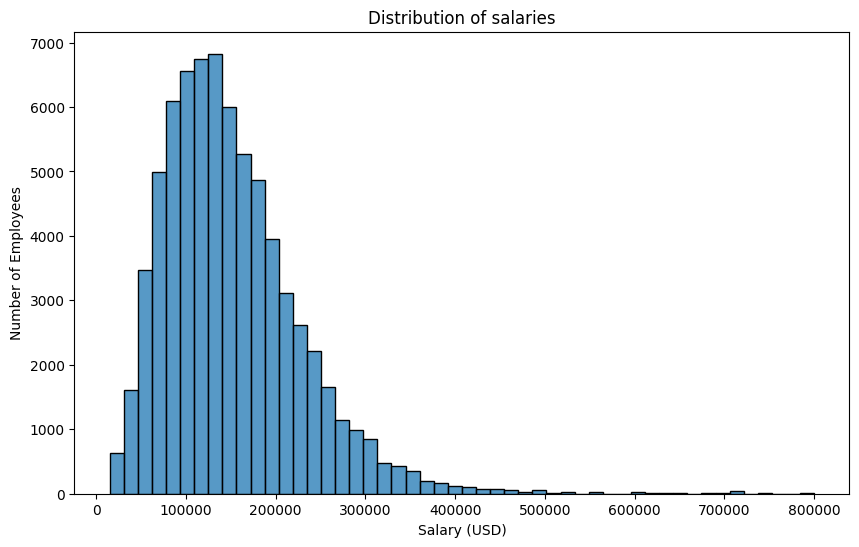

In [27]:
plt.close()
plt.figure(figsize=(10,6))

sns.histplot(
    data = df,
    x="salary_in_usd",
    bins = 50
)
plt.title("Distribution of salaries")
plt.xlabel("Salary (USD)")
plt.ylabel("Number of Employees")
plt.show()